In [139]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV, ElasticNetCV
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

from build_lagged_features import DATE, DEFAULT_LAGS, TARGET, build_lagged_frame, read_table

from functions import metrics, extract_lags_ols, lags_restrict, data_preprocessing, scaling, print_scaler

In [140]:
print(metrics)

<function metrics at 0x000002ABA38DBD80>


In [141]:
# Read data
df = pd.read_excel("chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")

# Order dates
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

## Constructing Lagged Variables

In [142]:
# Lagged frame
df_lagged = build_lagged_frame(df, lag_spec=DEFAULT_LAGS)

In [143]:
# Separate features (X) and target (y)
feature_cols = [c for c in df_lagged.columns if c not in [DATE, TARGET]]

X = df_lagged[feature_cols]
y = df_lagged[TARGET]

## OLS Regression (with default lags)

In [144]:
# Chronological Train/Test Split (Train < 2023, Test >= 2023)
train_mask = df_lagged[DATE] < "2023-01-01"

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]


# OLS Regression
model_ols = LinearRegression(fit_intercept=True)
model_ols.fit(X_train, y_train)
y_pred_test = model_ols.predict(X_test)


In [145]:
# Métricas para X_test
r2 = r2_score(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
mape = mean_absolute_percentage_error(y_test, y_pred_test)

print(f"R2: {r2}\n"
      f"MAE: {mae}\n"
      f"MSE: {mse}\n"
      f"RMSE: {rmse}\n"
      f"MAPE: {mape}")

R2: 0.5035694401864308
MAE: 0.2243488116555645
MSE: 0.29931942590495525
RMSE: 0.5471009284446109
MAPE: 0.11839472434277365


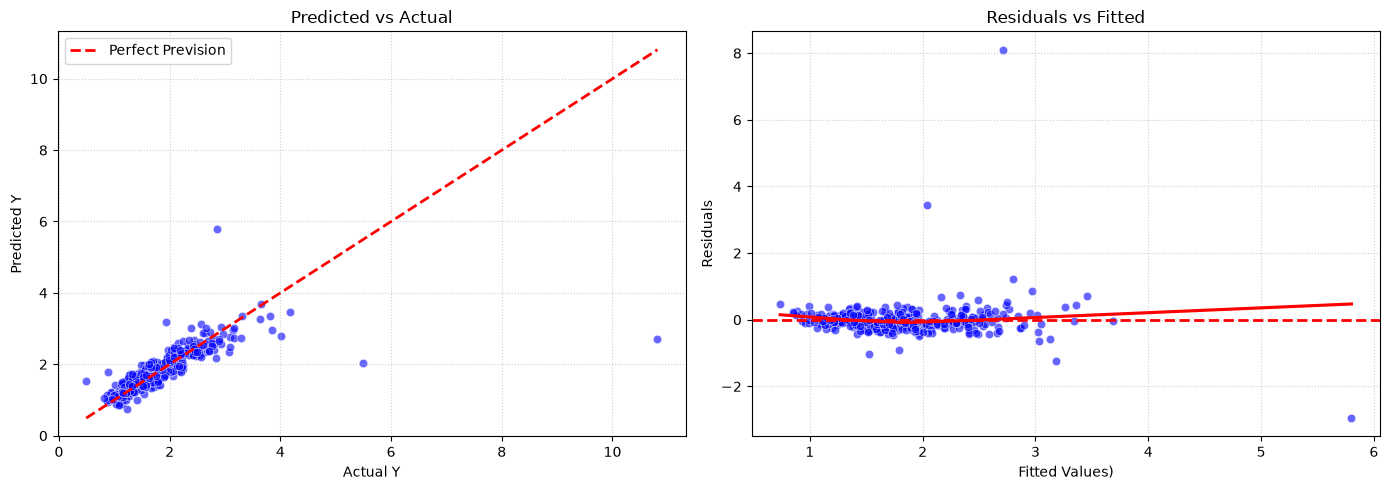

In [146]:
# Gráficos para visualizar a qualidade da regressão linear

residuals = y_test - y_pred_test    # Resíduo = Valor Real - Valor Previsto

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))   # Configurar a área dos gráficos (1 linha, 2 colunas)


# Gráfico1: Valores Previstos vs Valores Reais (Predicted vs Actual)
sns.scatterplot(x=y_test, y=y_pred_test, ax=ax1, alpha=0.6, color='blue')

lims = [np.min([y_test.min(), y_pred_test.min()]), 
        np.max([y_test.max(), y_pred_test.max()])]
ax1.plot(lims, lims, color='red', linestyle='--', lw=2, label='Perfect Prevision')

ax1.set_title('Predicted vs Actual')
ax1.set_xlabel('Actual Y')
ax1.set_ylabel('Predicted Y')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)


# Gráfico2: Resíduos vs Valores Ajustados/Previstos (Residuals vs Fitted)
sns.scatterplot(x=y_pred_test, y=residuals, ax=ax2, alpha=0.6, color='blue')

ax2.axhline(y=0, color='red', linestyle='--', lw=2)  # Linha onde o erro seria nulo

sns.regplot(x=y_pred_test, y=residuals, ax=ax2, scatter=False, color='red', lowess=True) # linha de tendência suave para detetar padrões não-lineares

ax2.set_title('Residuals vs Fitted')
ax2.set_xlabel('Fitted Values)')
ax2.set_ylabel('Residuals')
ax2.grid(True, linestyle=':', alpha=0.6)


plt.tight_layout()
plt.show()

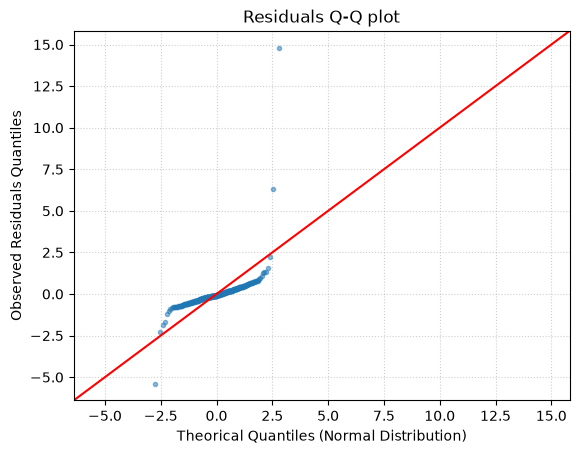

In [147]:
# Gráfico Q-Q
fig = sm.qqplot(residuals, line='45', fit=True) # 'line="45"' adiciona a linha de referência ideal da distribuição normal

fig.gca().lines[0].set_markersize(3)
fig.gca().lines[0].set_alpha(0.5)

plt.title('Residuals Q-Q plot')
plt.xlabel('Theorical Quantiles (Normal Distribution)')
plt.ylabel('Observed Residuals Quantiles')
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

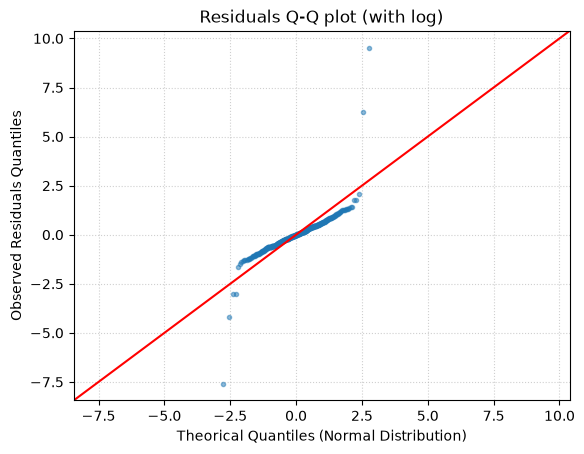

In [148]:
# Transformar a variável y (treino e teste) usando o logaritmo natural
y_train_log = np.log1p(y_train)  # np.log1p é mais seguro pois lida com valores zero: log(x + 1)
y_test_log = np.log1p(y_test)

# Ajustar o novo modelo
X = sm.add_constant(X_train)
model_log = sm.OLS(y_train_log, X).fit()


X_test_const = sm.add_constant(X_test)
y_pred_log = model_log.predict(X_test_const)
residuals_log = y_test_log - y_pred_log


# Gráfico Q-Q com log
fig = sm.qqplot(residuals_log, line='45', fit=True) # 'line="45"' adiciona a linha de referência ideal da distribuição normal

fig.gca().lines[0].set_markersize(3)
fig.gca().lines[0].set_alpha(0.5)

plt.title('Residuals Q-Q plot (with log)')
plt.xlabel('Theorical Quantiles (Normal Distribution)')
plt.ylabel('Observed Residuals Quantiles')
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

## Ridge and Lasso Regression (with default lags)

In [149]:
df_lagged = build_lagged_frame(df, lag_spec=DEFAULT_LAGS)

feature_cols = [c for c in df_lagged.columns if c not in [DATE, TARGET]]

X = df_lagged[feature_cols]
y = df_lagged[TARGET]
dates = df_lagged[DATE]

# Chronological Train/Test Split (Train < 2023, Test >= 2023)
train_mask = df_lagged[DATE] < "2023-01-01"
test_mask = (df_lagged[DATE] >= '2023-01-01') & (df_lagged[DATE] <= '2023-12-31')

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]
dates_test = df_lagged.loc[test_mask, DATE]

In [150]:
# Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [151]:
# Validação Cruzada
tscv = TimeSeriesSplit(n_splits=4, test_size=365)  # (4 splits = 1º bloco de treino de 4 anos + 4 blocos de validação de 1 ano)

# Intervalo de alphas para teste
alphas_ridge = np.logspace(-2, 6, 400)

# Modelo Ridge com Validação Cruzada
ridge_cv = RidgeCV(alphas=alphas_ridge, cv=tscv, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train_scaled, y_train)

y_pred_ridge = ridge_cv.predict(X_test_scaled)

# Métricas Ridge
r2_ridge = r2_score(y_test, y_pred_ridge)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
mape_ridge = mean_absolute_percentage_error(y_test, y_pred_ridge)

print(f"R2: {r2_ridge}\n"
      f"MAE: {mae_ridge}\n"
      f"RMSE: {rmse_ridge}\n"
      f"MSE: {mse_ridge}\n"
      f"MAPE: {mape_ridge}\n")

print(f"Melhor Alpha escolhido: {ridge_cv.alpha_:.4f}")

R2: 0.5104494546859357
MAE: 0.22280212242459718
RMSE: 0.5432965746327243
MSE: 0.2951711680076514
MAPE: 0.117648643620575

Melhor Alpha escolhido: 81.2408


In [152]:
# Modelo Lasso com Validação Cruzada
tscv = TimeSeriesSplit(n_splits=4, test_size=365)
alphas_lasso = np.logspace(-5, 1, 300)

lasso_cv = LassoCV(alphas=alphas_lasso, cv=tscv, max_iter=10000, random_state=42)
lasso_cv.fit(X_train_scaled, y_train)

# Previsões
y_pred_lasso = lasso_cv.predict(X_test_scaled)

# Métricas Lasso
r2_lasso = r2_score(y_test, y_pred_lasso)
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
mape_lasso = mean_absolute_percentage_error(y_test, y_pred_lasso)

print(f"R2: {r2_lasso}\n"
      f"MAE: {mae_lasso}\n"
      f"RMSE: {rmse_lasso}\n"
      f"MSE: {mse_lasso}\n"
      f"MAPE: {mape_lasso}")

R2: 0.5136505217485289
MAE: 0.21746166250685317
RMSE: 0.5415174110016527
MSE: 0.2932411064179329
MAPE: 0.11461525164806022


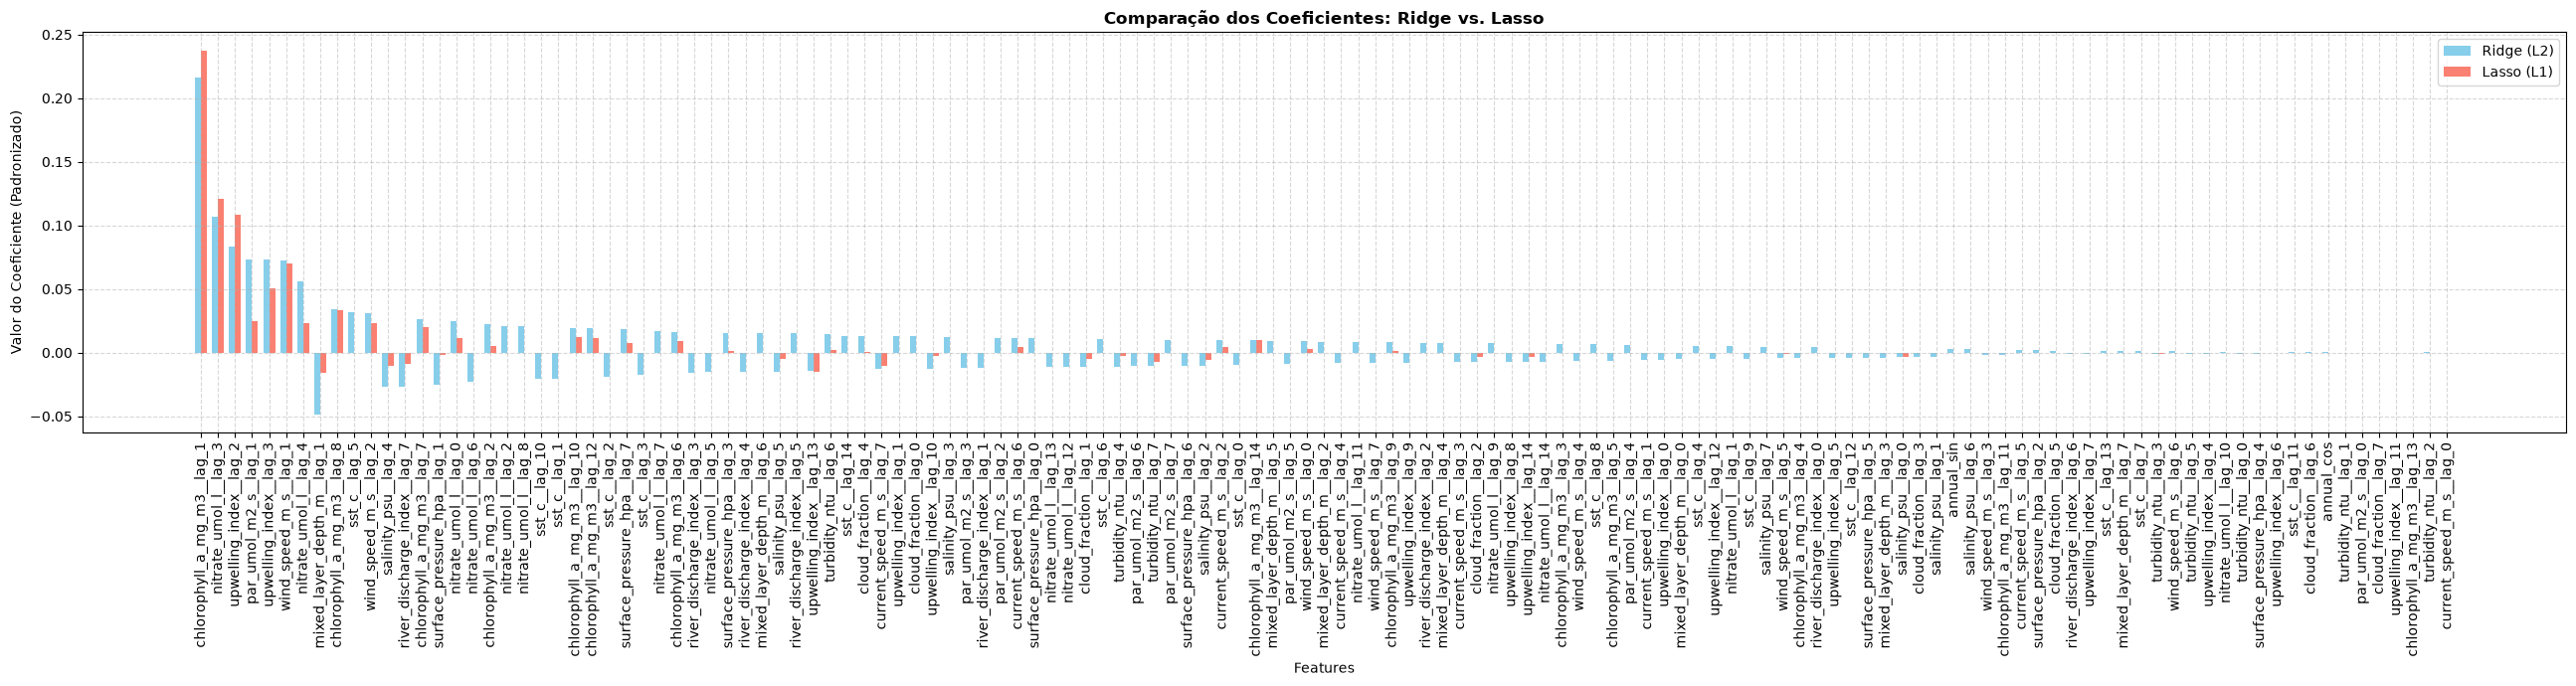

In [153]:
# DataFrame de coeficientes
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Ridge_Coef': ridge_cv.coef_,
    'Lasso_Coef': lasso_cv.coef_
}).sort_values(by='Ridge_Coef', key=abs, ascending=False)

# Visualização gráfica dos coeficientes
plt.figure(figsize=(26, 7))
x_indices = np.arange(len(coef_df))
width = 0.35

plt.bar(x_indices - width/2, coef_df['Ridge_Coef'], width, label='Ridge (L2)', color='skyblue')
plt.bar(x_indices + width/2, coef_df['Lasso_Coef'], width, label='Lasso (L1)', color='salmon')

plt.xlabel('Features')
plt.ylabel('Valor do Coeficiente (Padronizado)')
plt.title('Comparação dos Coeficientes: Ridge vs. Lasso', fontsize=12, fontweight='bold')
plt.xticks(x_indices, coef_df['Feature'], rotation=90)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [154]:
# Contagem de variáveis zeradas pelo Lasso
zeroed_features = coef_df[coef_df['Lasso_Coef'] == 0]['Feature'].tolist()
print(f"\nVariáveis totalmente zeradas pelo Lasso ({len(zeroed_features)}): {zeroed_features}")


Variáveis totalmente zeradas pelo Lasso (91): ['sst_c__lag_5', 'nitrate_umol_l__lag_6', 'nitrate_umol_l__lag_2', 'nitrate_umol_l__lag_8', 'sst_c__lag_10', 'sst_c__lag_1', 'sst_c__lag_2', 'sst_c__lag_3', 'nitrate_umol_l__lag_7', 'river_discharge_index__lag_3', 'nitrate_umol_l__lag_5', 'river_discharge_index__lag_4', 'mixed_layer_depth_m__lag_6', 'river_discharge_index__lag_5', 'sst_c__lag_14', 'upwelling_index__lag_1', 'cloud_fraction__lag_0', 'salinity_psu__lag_3', 'par_umol_m2_s__lag_3', 'river_discharge_index__lag_1', 'par_umol_m2_s__lag_2', 'surface_pressure_hpa__lag_0', 'nitrate_umol_l__lag_13', 'nitrate_umol_l__lag_12', 'sst_c__lag_6', 'par_umol_m2_s__lag_6', 'par_umol_m2_s__lag_7', 'surface_pressure_hpa__lag_6', 'sst_c__lag_0', 'mixed_layer_depth_m__lag_5', 'par_umol_m2_s__lag_5', 'mixed_layer_depth_m__lag_2', 'current_speed_m_s__lag_4', 'nitrate_umol_l__lag_11', 'wind_speed_m_s__lag_7', 'upwelling_index__lag_9', 'river_discharge_index__lag_2', 'mixed_layer_depth_m__lag_4', 'cur

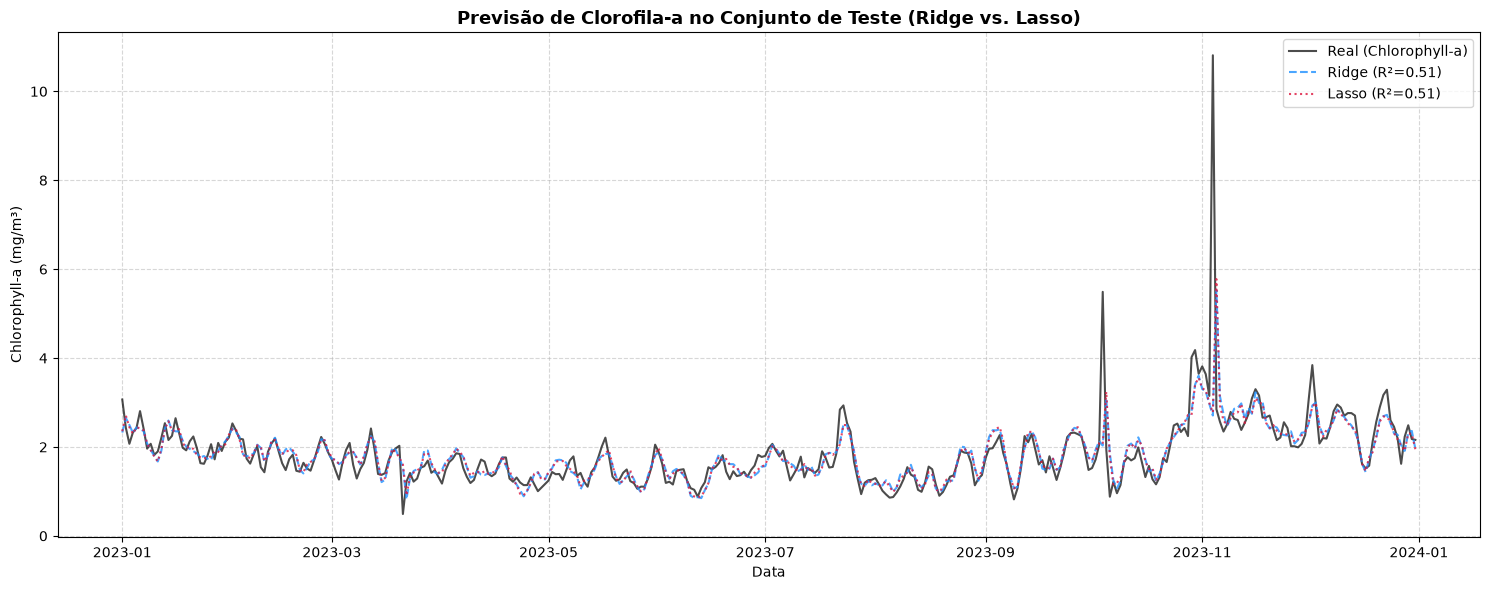

In [155]:
plt.figure(figsize=(15, 6))
plt.plot(dates_test, y_test.values, label='Real (Chlorophyll-a)', color='black', alpha=0.7, linewidth=1.5)
plt.plot(dates_test, y_pred_ridge, label=f'Ridge (R²={r2_ridge:.2f})', color='dodgerblue', linestyle='--', alpha=0.8)
plt.plot(dates_test, y_pred_lasso, label=f'Lasso (R²={r2_lasso:.2f})', color='crimson', linestyle=':', alpha=0.8)

plt.xlabel('Data')
plt.ylabel('Chlorophyll-a (mg/m³)')
plt.title('Previsão de Clorofila-a no Conjunto de Teste (Ridge vs. Lasso)', fontsize=13, fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Repeat the models (OLS, Ridge and Lasso) with log(Chlorophyll-a) and outliers cleaning

In [156]:
# Criar cópia e aplicar log(clorofila-a)
df_log = df.copy()
df_log['chlorophyll_a_mg_m3'] = np.log(df_log['chlorophyll_a_mg_m3'])


df_log_clean = df_log.copy()

train_dates_mask = df_log_clean[DATE] < '2023-01-01'
y_train_log = df_log_clean.loc[train_dates_mask, 'chlorophyll_a_mg_m3']

# IQR no y train (em log)
Q1 = y_train_log.quantile(0.25)
Q3 = y_train_log.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_mask = train_dates_mask & (
    (df_log_clean['chlorophyll_a_mg_m3'] < lower_bound) | 
    (df_log_clean['chlorophyll_a_mg_m3'] > upper_bound)
)

# Interpolar (média entre o dia anterior e o seguinte)
df_log_clean.loc[outliers_mask, 'chlorophyll_a_mg_m3'] = np.nan
df_log_clean['chlorophyll_a_mg_m3'] = df_log_clean['chlorophyll_a_mg_m3'].interpolate(method='linear')



# Lags
df_lagged = build_lagged_frame(df_log_clean, lag_spec=DEFAULT_LAGS)

train_mask = df_lagged[DATE] < '2023-01-01'
test_mask = (df_lagged[DATE] >= '2023-01-01') & (df_lagged[DATE] <= '2023-12-31')

X_train = df_lagged.loc[train_mask].drop(columns=['date', 'chlorophyll_a_mg_m3'])
y_train_log = df_lagged.loc[train_mask, 'chlorophyll_a_mg_m3']

X_test = df_lagged.loc[test_mask].drop(columns=['date', 'chlorophyll_a_mg_m3'])
y_test_log = df_lagged.loc[test_mask, 'chlorophyll_a_mg_m3']

dates_test = df_lagged.loc[test_mask, 'date']
y_test_orig = df.loc[df['date'].isin(dates_test), 'chlorophyll_a_mg_m3'].values  # guardar o target original (sem log)


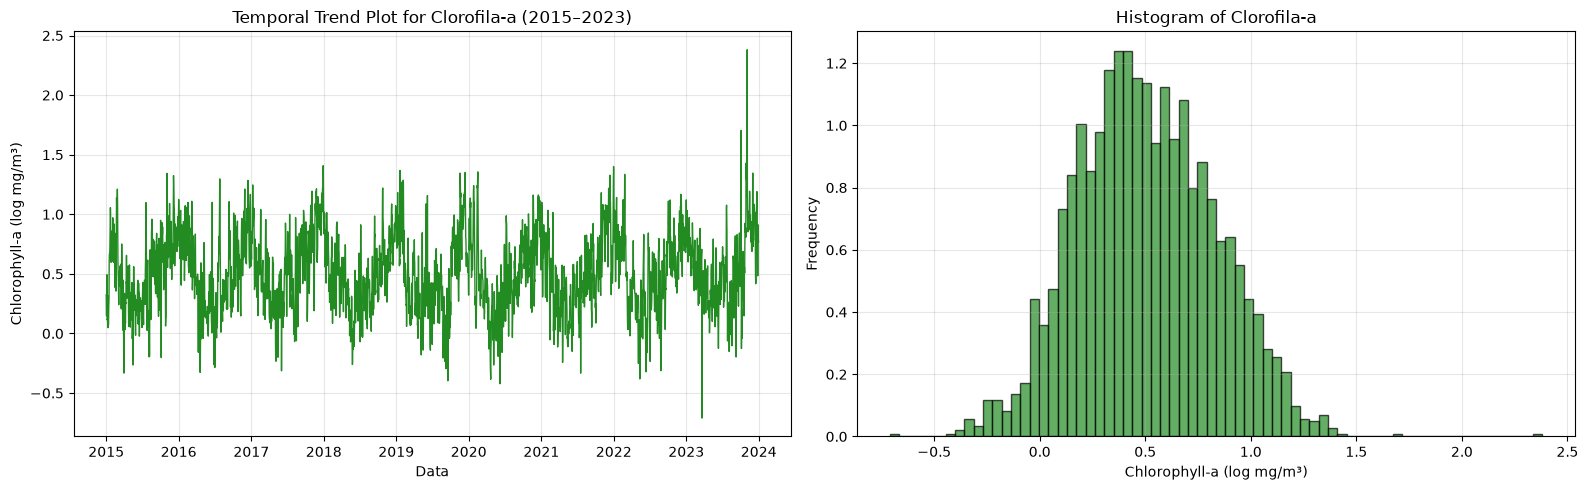

In [157]:
# Gráficos da clorofila com log e tratamento de outliers:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico Temporal
ax1.plot(df_log_clean['date'], df_log_clean['chlorophyll_a_mg_m3'], color='forestgreen', linewidth=1)
ax1.set_title('Temporal Trend Plot for Clorofila-a (2015–2023)')
ax1.set_xlabel('Data')
ax1.set_ylabel('Chlorophyll-a (log mg/m³)')
ax1.grid(True, alpha=0.3)

# Histograma
ax2.hist(
    df_log_clean['chlorophyll_a_mg_m3'], 
    bins=70, 
    density=True, 
    color='forestgreen', 
    edgecolor='black', 
    alpha=0.7
)
ax2.set_title('Histogram of Clorofila-a')
ax2.set_xlabel('Chlorophyll-a (log mg/m³)')
ax2.set_ylabel('Frequency')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [158]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [159]:
tscv = TimeSeriesSplit(n_splits=4, test_size=365) 

In [160]:
# OLS
ols = LinearRegression(fit_intercept=True).fit(X_train_scaled, y_train_log)

y_pred_ols_log = ols.predict(X_test_scaled)
y_pred_ols = np.exp(y_pred_ols_log)  # Reversão log -> escala original


In [161]:
# Ridge
alphas_ridge = np.logspace(-2, 6, 400)
ridge_cv = RidgeCV(alphas=alphas_ridge, cv=tscv, scoring='neg_root_mean_squared_error')
ridge_cv.fit(X_train_scaled, y_train_log)

y_pred_ridge_log = ridge_cv.predict(X_test_scaled)
y_pred_ridge = np.exp(y_pred_ridge_log)  # Reversão log -> escala original

In [162]:
# Lasso
alphas_lasso = np.logspace(-5, 1, 300)
lasso_cv = LassoCV(alphas=alphas_lasso, cv=tscv, max_iter=20000, random_state=42)
lasso_cv.fit(X_train_scaled, y_train_log)

y_pred_lasso_log = lasso_cv.predict(X_test_scaled)
y_pred_lasso = np.exp(y_pred_lasso_log)  # Reversão log -> escala original

In [163]:
def calc_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mse = mean_squared_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    
    return r2, mae, rmse, mse, mape

metrics_result = {
    'OLS': calc_metrics(y_test_orig, y_pred_ols),
    'Ridge': calc_metrics(y_test_orig, y_pred_ridge),
    'Lasso': calc_metrics(y_test_orig, y_pred_lasso)
}


results_df = pd.DataFrame(metrics_result, index=['R²', 'MAE', 'RMSE', 'MSE', 'MAPE']).T
print("Resultados no conjunto de teste 2023 (escala original)")
print(results_df)
print(f"\nMelhor Alpha Ridge: {ridge_cv.alpha_:.4f}")
print(f"Melhor Alpha Lasso: {lasso_cv.alpha_:.4f}")

Resultados no conjunto de teste 2023 (escala original)
             R²       MAE      RMSE       MSE      MAPE
OLS    0.521826  0.200722  0.536946  0.288311  0.103809
Ridge  0.527264  0.199968  0.533885  0.285033  0.103542
Lasso  0.532018  0.197624  0.531193  0.282166  0.102084

Melhor Alpha Ridge: 17.7060
Melhor Alpha Lasso: 0.0007


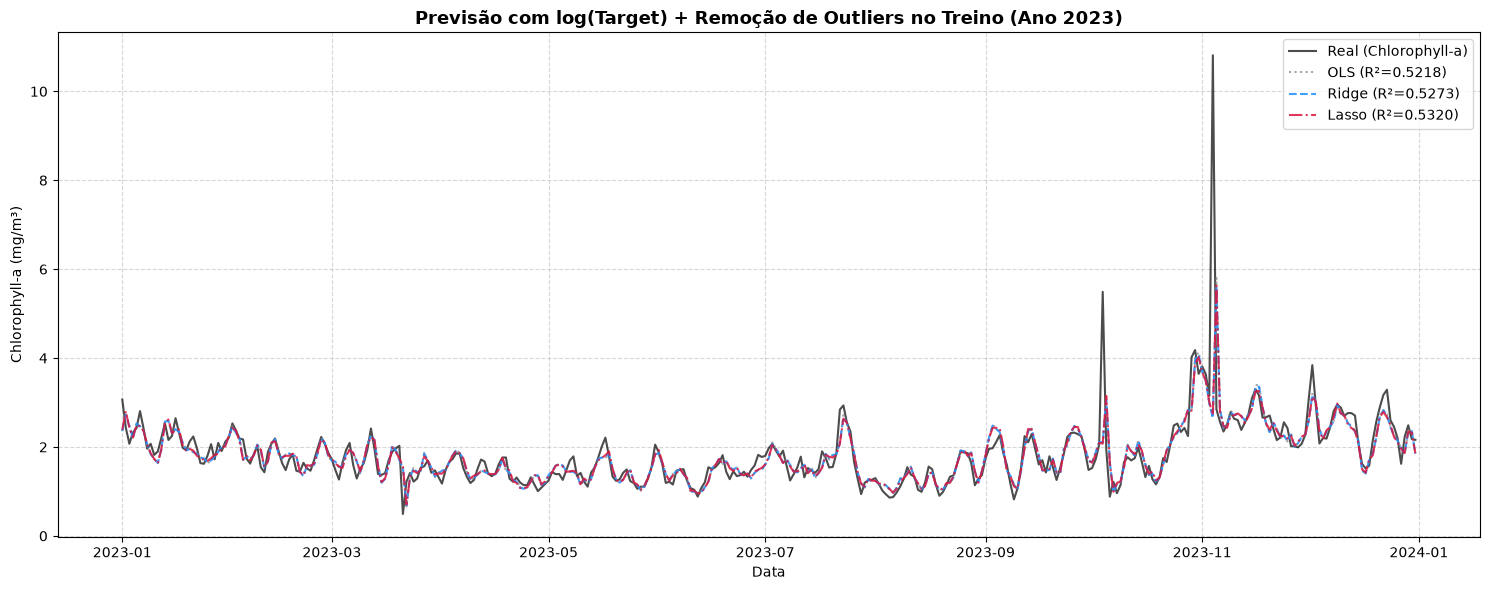

In [164]:
plt.figure(figsize=(15, 6))
plt.plot(dates_test, y_test_orig, label='Real (Chlorophyll-a)', color='black', alpha=0.7, linewidth=1.5)
plt.plot(dates_test, y_pred_ols, label=f'OLS (R²={metrics_result["OLS"][0]:.4f})', color='gray', linestyle=':', alpha=0.7)
plt.plot(dates_test, y_pred_ridge, label=f'Ridge (R²={metrics_result["Ridge"][0]:.4f})', color='dodgerblue', linestyle='--', alpha=0.85)
plt.plot(dates_test, y_pred_lasso, label=f'Lasso (R²={metrics_result["Lasso"][0]:.4f})', color='crimson', linestyle='-.', alpha=0.85)

plt.xlabel('Data')
plt.ylabel('Chlorophyll-a (mg/m³)')
plt.title('Previsão com log(Target) + Remoção de Outliers no Treino (Ano 2023)', fontsize=13, fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Retirar feature "par_umol_m2_s"

In [165]:
X_train, y_train, X_test, y_test_orig = data_preprocessing(
    df = df,                          
    selected_lags = None, 
    test_year = 2023,            
    log_y = True,                     
    clean_outliers = True,          
    clean_features = ['par_umol_m2_s'] 
)

print(f"Formato de X_train: {X_train.shape}")
print(f"Formato de X_test:  {X_test.shape}")
print(f"Amostras em y_test_orig: {len(y_test_orig)}")

Formato de X_train: (2908, 125)
Formato de X_test:  (365, 125)
Amostras em y_test_orig: 365


In [166]:
# Aplicar os modelos:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

tscv = TimeSeriesSplit(n_splits=4, test_size=365)


# OLS
ols = LinearRegression(fit_intercept=True).fit(X_train_scaled, y_train)

y_pred_ols = np.exp(ols.predict(X_test_scaled))  # Reversão log -> escala original




# Ridge
ridge = RidgeCV(
    alphas=np.logspace(-2, 6, 400), 
    cv=tscv, 
    scoring='neg_mean_squared_error'
)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = np.exp(ridge.predict(X_test_scaled))  # Reversão log -> escala original






# Lasso
lasso = LassoCV(
    alphas=np.logspace(-5, 1, 300), 
    cv=tscv, 
    max_iter=20000, 
    random_state=42
    )
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = np.exp(lasso.predict(X_test_scaled))

In [167]:
metrics(y_test_orig, y_pred_ols)

metrics(y_test_orig, y_pred_ridge)

metrics(y_test_orig, y_pred_lasso)

Metrics
R2: 0.5245566894486802
MAE: 0.20491903783084217
RMSE: 0.5354113436059059
MSE: 0.2866653068618814
MAPE: 0.10645616338507627
Metrics
R2: 0.5302343423757727
MAE: 0.20360383807839183
RMSE: 0.5322048521837541
MSE: 0.2832420046879316
MAPE: 0.10579834450383896
Metrics
R2: 0.5349184326328056
MAE: 0.20014757110821996
RMSE: 0.5295448652955178
MSE: 0.2804177643608481
MAPE: 0.10362081489854533


# Escolha de lags com base no teste t

### OLS Regression (mudança de lags)

In [168]:
X_train_sm = sm.add_constant(X_train_scaled)
ols_sm = sm.OLS(y_train, X_train_sm).fit()

print(ols_sm.summary().tables[0])
print(ols_sm.summary().tables[2])
print(ols_sm.summary().tables[1])

                             OLS Regression Results                            
Dep. Variable:     chlorophyll_a_mg_m3   R-squared:                       0.862
Model:                             OLS   Adj. R-squared:                  0.855
Method:                  Least Squares   F-statistic:                     138.7
Date:                 Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                         22:31:12   Log-Likelihood:                 2036.1
No. Observations:                 2908   AIC:                            -3820.
Df Residuals:                     2782   BIC:                            -3067.
Df Model:                          125                                         
Covariance Type:             nonrobust                                         
Omnibus:                      391.841   Durbin-Watson:                   2.001
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4993.351
Skew:                           0.017   Pr

In [169]:
selected_lags = extract_lags_ols(X_train_scaled, y_train, alpha=0.1)

Total de coeficientes analisados: 125
Lags significativas encontradas (p < 0.1): 18


In [170]:
X_train, y_train, X_test, y_test_orig = data_preprocessing(
    df = df,                          
    selected_lags = selected_lags, 
    test_year = 2023,            
    log_y = True,                     
    clean_outliers = True,          
    clean_features = ['par_umol_m2_s'] 
)

['par_umol_m2_s', 'current_speed_m_s', 'surface_pressure_hpa']
print(f"Formato de X_train: {X_train.shape}")
print(f"Formato de X_test:  {X_test.shape}")
print(f"Amostras em y_test_orig: {len(y_test_orig)}")

Formato de X_train: (2908, 2)
Formato de X_test:  (365, 2)
Amostras em y_test_orig: 365


In [171]:
# Aplicar os modelos:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

tscv = TimeSeriesSplit(n_splits=4, test_size=365)


# OLS
ols = LinearRegression(fit_intercept=True).fit(X_train_scaled, y_train)

y_pred_ols = np.exp(ols.predict(X_test_scaled))  # Reversão log -> escala original




# Ridge
ridge = RidgeCV(
    alphas=np.logspace(-2, 6, 400), 
    cv=tscv, 
    scoring='neg_mean_squared_error'
)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = np.exp(ridge.predict(X_test_scaled))  # Reversão log -> escala original






# Lasso
lasso = LassoCV(
    alphas=np.logspace(-5, 1, 300), 
    cv=tscv, 
    max_iter=20000, 
    random_state=42
    )
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = np.exp(lasso.predict(X_test_scaled))

In [172]:
metrics(y_test_orig, y_pred_ols)

metrics(y_test_orig, y_pred_ridge)

metrics(y_test_orig, y_pred_lasso)

Metrics
R2: 0.2407660158916345
MAE: 0.3698893466283319
RMSE: 0.676590689551152
MSE: 0.45777496118730326
MAPE: 0.19340513401550316
Metrics
R2: 0.24076555454421744
MAE: 0.36988945539483364
RMSE: 0.6765908951157908
MSE: 0.45777523935358705
MAPE: 0.19340514694274208
Metrics
R2: 0.2407558523546034
MAE: 0.36989145169014026
RMSE: 0.6765952181494884
MSE: 0.45778108922275385
MAPE: 0.19340519181786026


# Experiências

In [173]:
# usámos este código para fazer experiências
# fomos mudando os valores dos argumentos das funções e registando os resultados à parte
# durante as experiências, pode ser necessário colocar código comentado ou tirar código que esteja nos comentários
# (isto foi apenas uma forma inicial de ver algumas previões de resultados, as conclusões finais foram feitas com base nos reultados do grid search)

# Read data
df = pd.read_excel("chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")

# Order dates
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)


# processamento dos dados (experimentar várias combinações)
X_train, y_train, X_test, y_test_orig = data_preprocessing(
    df = df,                          
    selected_lags = None, 
    test_year = 2022,            
    log_y = True,                     
    clean_outliers = False,          
    clean_features = ['par_umol_m2_s', 'current_speed_m_s', 'surface_pressure_hpa']
)



# para lags:
selected_lags = extract_lags_ols(X_train, y_train, alpha=0.1)


X_train, y_train, X_test, y_test_orig = data_preprocessing(
    df = df,                          
    selected_lags = selected_lags, 
    test_year = 2022,            
    log_y = True,                     
    clean_outliers = False,          
    clean_features = ['par_umol_m2_s', 'current_speed_m_s', 'surface_pressure_hpa']
)


# clean_features = ['par_umol_m2_s', 'current_speed_m_s', 'surface_pressure_hpa']

# select_lags dos coeficientes que não foram zerados pelo lasso:
#['chlorophyll_a_mg_m3__lag_1', 'chlorophyll_a_mg_m3__lag_3', 'chlorophyll_a_mg_m3__lag_4', 'chlorophyll_a_mg_m3__lag_6', 'chlorophyll_a_mg_m3__lag_7', 'chlorophyll_a_mg_m3__lag_8', 'chlorophyll_a_mg_m3__lag_9', 'chlorophyll_a_mg_m3__lag_12', 'chlorophyll_a_mg_m3__lag_13', 'chlorophyll_a_mg_m3__lag_14', 'sst_c__lag_5', 'nitrate_umol_l__lag_3', 'nitrate_umol_l__lag_4', 'nitrate_umol_l__lag_5', 'nitrate_umol_l__lag_13', 'wind_speed_m_s__lag_0', 'wind_speed_m_s__lag_1', 'wind_speed_m_s__lag_2', 'wind_speed_m_s__lag_7', 'upwelling_index__lag_2', 'upwelling_index__lag_3', 'upwelling_index__lag_10', 'upwelling_index__lag_13', 'upwelling_index__lag_14', 'mixed_layer_depth_m__lag_1', 'salinity_psu__lag_0', 'salinity_psu__lag_2', 'salinity_psu__lag_4', 'salinity_psu__lag_5', 'river_discharge_index__lag_7', 'cloud_fraction__lag_0', 'cloud_fraction__lag_2', 'cloud_fraction__lag_3', 'turbidity_ntu__lag_4', 'turbidity_ntu__lag_7']


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

tscv = TimeSeriesSplit(n_splits=4, test_size=365)


# OLS
ols = LinearRegression(fit_intercept=True).fit(X_train_scaled, y_train)

#y_pred_ols=ols.predict(X_test_scaled)
y_pred_ols = np.exp(ols.predict(X_test_scaled))  # Reversão log -> escala original


# Ridge
ridge = RidgeCV(
    alphas=np.logspace(-2, 6, 400), 
    cv=tscv, 
    scoring='neg_mean_squared_error'
)
ridge.fit(X_train_scaled, y_train)

#y_pred_ridge=ridge.predict(X_test_scaled)
y_pred_ridge = np.exp(ridge.predict(X_test_scaled))  # Reversão log -> escala original


# Lasso
lasso = LassoCV(
    alphas=np.logspace(-5, 1, 300), 
    cv=tscv, 
    max_iter=20000, 
    random_state=42
    )
lasso.fit(X_train_scaled, y_train)

#y_pred_lasso = lasso.predict(X_test_scaled)
y_pred_lasso = np.exp(lasso.predict(X_test_scaled))


# Elastic Net
enet = ElasticNetCV(
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99],
    alphas=np.logspace(-5, 1, 300),
    cv=tscv,
    max_iter=20000,
    random_state=42
)
enet.fit(X_train_scaled, y_train)

#y_pred_enet = enet.predict(X_test_scaled)
y_pred_enet = np.exp(enet.predict(X_test_scaled))



print("OLS:")
metrics(y_test_orig, y_pred_ols)

print(f"\n Ridge:")
metrics(y_test_orig, y_pred_ridge)

print(f"\n Lasso:")
metrics(y_test_orig, y_pred_lasso)

print(f"\n Elastic Net:")
metrics(y_test_orig, y_pred_enet)

Total de coeficientes analisados: 109
Lags significativas encontradas (p < 0.1): 14
OLS:
Metrics
R2: 0.842170315370965
MAE: 0.1600739680803634
RMSE: 0.22034055749532253
MSE: 0.04854996127734953
MAPE: 0.09489415584558027

 Ridge:
Metrics
R2: 0.8421697696549283
MAE: 0.1600741234765891
RMSE: 0.22034093842262434
MSE: 0.048550129144962734
MAPE: 0.09489422795109313

 Lasso:
Metrics
R2: 0.8422103168576788
MAE: 0.16006088252192052
RMSE: 0.22031263338065957
MSE: 0.04853765642712091
MAPE: 0.09488723238372729

 Elastic Net:
Metrics
R2: 0.842173073017837
MAE: 0.16007301518222866
RMSE: 0.2203386325592602
MSE: 0.04854911299808468
MAPE: 0.09489362851991476


In [174]:
# para selecionar as lags totalmente zeradas pelo Lasso
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Lasso_Coef': lasso.coef_
})

zeroed_features = coef_df[coef_df['Lasso_Coef'] != 0]['Feature'].tolist()
print(f"\nVariáveis totalmente zeradas pelo Lasso ({len(zeroed_features)}): {zeroed_features}")


Variáveis totalmente zeradas pelo Lasso (16): ['annual_sin', 'annual_cos', 'chlorophyll_a_mg_m3__lag_1', 'chlorophyll_a_mg_m3__lag_6', 'chlorophyll_a_mg_m3__lag_7', 'chlorophyll_a_mg_m3__lag_8', 'chlorophyll_a_mg_m3__lag_12', 'sst_c__lag_5', 'nitrate_umol_l__lag_3', 'nitrate_umol_l__lag_4', 'wind_speed_m_s__lag_1', 'upwelling_index__lag_2', 'upwelling_index__lag_3', 'mixed_layer_depth_m__lag_1', 'cloud_fraction__lag_0', 'turbidity_ntu__lag_4']
